# 03 - Modeling
**Project:** Credit Approval Readiness — predicting credit card approval odds

**Goal of this notebook:**
1. Train a baseline model (Logistic Regression) — interpretable, good starting point
2. Train a stronger model (Random Forest) for comparison
3. Evaluate both with metrics that matter for imbalanced classification
4. Use SHAP to explain *why* the best model predicts what it does — this is what turns the project into actionable advice, not just a classifier

Loads the cleaned dataset produced by `01_data_cleaning.ipynb`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)
pd.set_option('display.max_columns', None)

RANDOM_STATE = 42  # fixed seed so results are reproducible each time this notebook runs

## 1. Load the cleaned data

In [2]:
df = pd.read_csv('../data/processed/cc_approvals_clean.csv')

print(f"Shape: {df.shape}")
df.head()

Shape: (690, 16)


,gender,age,debt,married,bank_customer,education_level,ethnicity,years_employed,prior_default,employed,credit_score,drivers_license,citizen,zip_code,income,approved
0,b,30.83,0.000,u,g,w,v,1.25,t,t,1,f,g,202,0,1
1,a,58.67,4.460,u,g,q,h,3.04,t,t,6,f,g,43,560,1
2,a,24.50,0.500,u,g,q,h,1.50,t,f,0,f,g,280,824,1
3,b,27.83,1.540,u,g,w,v,3.75,t,t,5,t,g,100,3,1
4,b,20.17,5.625,u,g,w,v,1.71,t,f,0,f,s,120,0,1


## 2. Prepare features (X) and target (y)

Models need every input to be numeric — categorical columns (text values) have to be converted first.
`pd.get_dummies()` one-hot encodes them: each category becomes its own 0/1 column.

In [3]:
target_col = 'approved'

X = df.drop(columns=[target_col])
y = df[target_col]

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
print(f"Encoding categorical columns: {categorical_cols}")

X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print(f"\nFeature matrix shape after encoding: {X.shape}")
X.head()

Encoding categorical columns: ['gender', 'married', 'bank_customer', 'education_level', 'ethnicity', 'prior_default', 'employed', 'drivers_license', 'citizen']

Feature matrix shape after encoding: (690, 37)


/var/folders/cn/7pxxg23s6p1_p4j6jxwqd_rw0000gn/T/ipykernel_1224/1831423204.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=['object']).columns.tolist()


,age,debt,years_employed,credit_score,zip_code,income,gender_b,married_u,married_y,bank_customer_gg,bank_customer_p,education_level_c,education_level_cc,education_level_d,education_level_e,education_level_ff,education_level_i,education_level_j,education_level_k,education_level_m,education_level_q,education_level_r,education_level_w,education_level_x,ethnicity_dd,ethnicity_ff,ethnicity_h,ethnicity_j,ethnicity_n,ethnicity_o,ethnicity_v,ethnicity_z,prior_default_t,employed_t,drivers_license_t,citizen_p,citizen_s
0,30.83,0.000,1.25,1,202,0,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,True,True,False,False,False
1,58.67,4.460,3.04,6,43,560,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,True,True,False,False,False
2,24.50,0.500,1.50,0,280,824,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False
3,27.83,1.540,3.75,5,100,3,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,True,True,True,False,False
4,20.17,5.625,1.71,0,120,0,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,True,False,False,False,True


## 3. Train/test split

Hold out a portion of the data the model never sees during training, so we can evaluate honestly
on data it hasn't memorized. `stratify=y` keeps the same approval/denial ratio in both the train
and test sets — important given the class imbalance we saw in EDA.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train shape: {X_train.shape}")
print(f"Test shape: {X_test.shape}")
print(f"\nTrain approval rate: {y_train.mean():.1%}")
print(f"Test approval rate: {y_test.mean():.1%}")

Train shape: (552, 37)
Test shape: (138, 37)

Train approval rate: 44.6%
Test approval rate: 44.2%


## 4. Baseline model — Logistic Regression

We scale the features first since Logistic Regression is sensitive to features being on very
different numeric ranges (recall income/credit_score had very different scales in EDA).

In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced')
log_reg.fit(X_train_scaled, y_train)

y_pred_log = log_reg.predict(X_test_scaled)
y_proba_log = log_reg.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression trained.")

Logistic Regression trained.


**Note on `class_weight='balanced'`:** this tells the model to pay proportionally more attention
to the minority class during training, rather than assuming both classes are equally common — a
direct response to the imbalance we measured in the EDA notebook.

## 5. Comparison model — Random Forest

In [6]:
rf = RandomForestClassifier(
    n_estimators=200, random_state=RANDOM_STATE, class_weight='balanced'
)
rf.fit(X_train, y_train)  # tree-based models don't require feature scaling

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print("Random Forest trained.")

Random Forest trained.


## 6. Evaluate both models

Given the class imbalance, **accuracy alone is misleading** (see the EDA notebook's note on this).
Precision, recall, and ROC-AUC give a fuller picture:
- **Precision:** of everyone the model predicted "approved," how many actually were?
- **Recall:** of everyone actually approved, how many did the model catch?
- **ROC-AUC:** overall ability to distinguish approved vs. denied across all thresholds (0.5 = random guessing, 1.0 = perfect)

In [9]:
def evaluate_model(name, y_true, y_pred, y_proba):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba),
    }

results = pd.DataFrame([
    evaluate_model('Logistic Regression', y_test, y_pred_log, y_proba_log),
    evaluate_model('Random Forest', y_test, y_pred_rf, y_proba_rf),
])

results.set_index('Model').round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.870,0.831,0.885,0.857,0.946
Random Forest,0.884,0.881,0.852,0.867,0.954


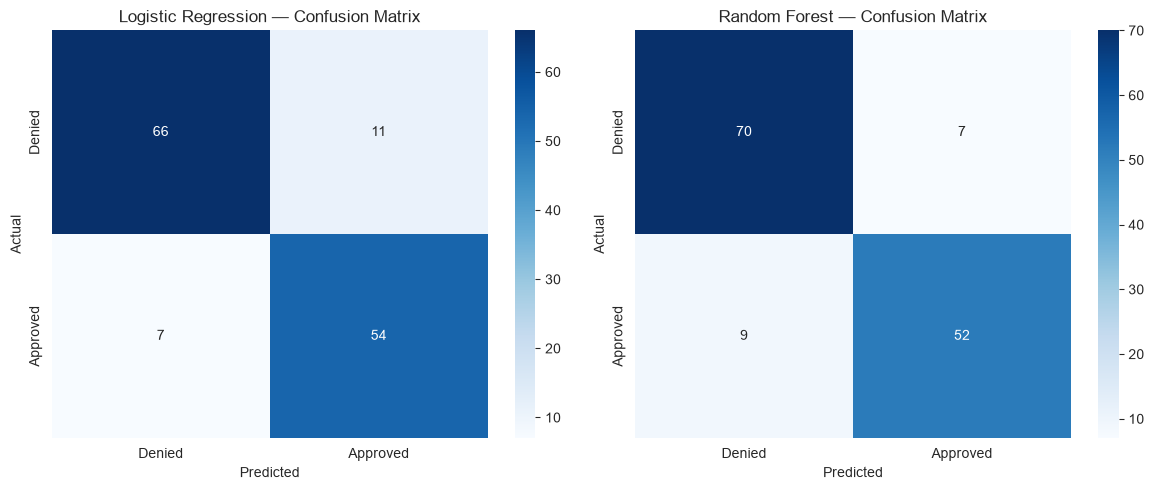

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (y_pred, name) in zip(axes, [(y_pred_log, 'Logistic Regression'), (y_pred_rf, 'Random Forest')]):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Denied', 'Approved'], yticklabels=['Denied', 'Approved'])
    ax.set_title(f'{name} — Confusion Matrix')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.savefig('../reports/figures/confusion_matrices.png', dpi=150)
plt.show()

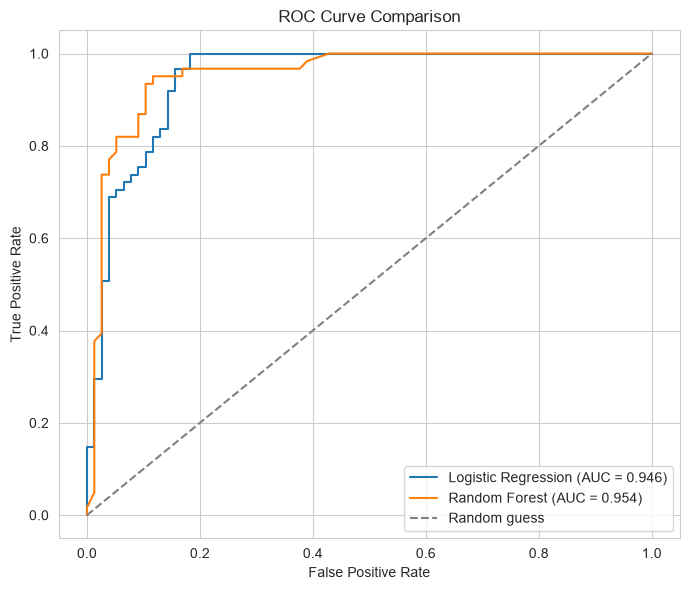

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))

for y_proba, name in [(y_proba_log, 'Logistic Regression'), (y_proba_rf, 'Random Forest')]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve Comparison')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/figures/roc_curve.png', dpi=150)
plt.show()

## 7. Feature importance — Logistic Regression coefficients

For Logistic Regression, the coefficients directly tell us direction and relative strength: positive
coefficients push toward approval, negative push toward denial.

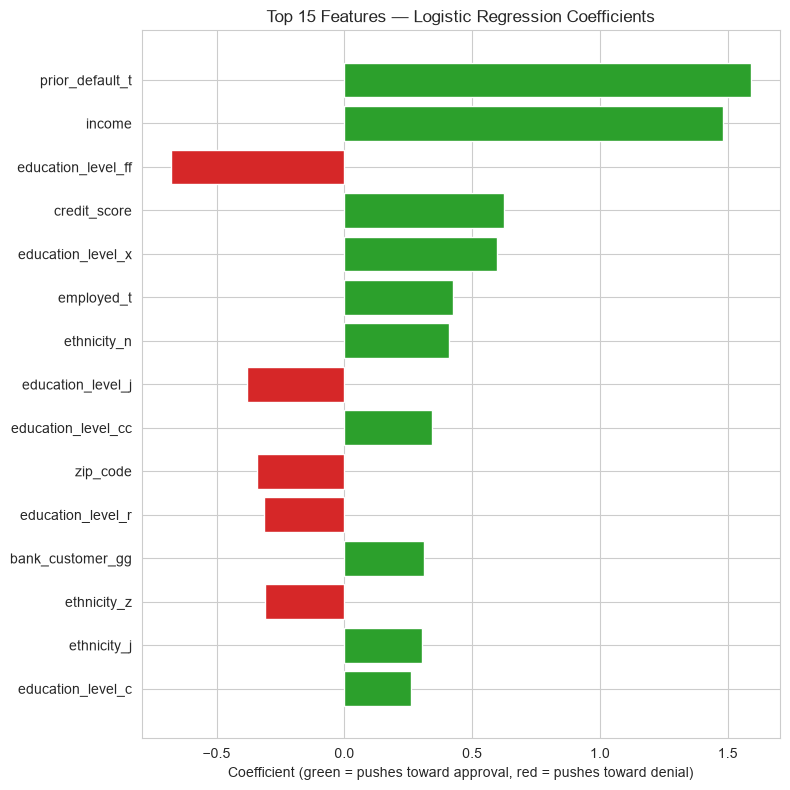

In [12]:
log_reg_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': log_reg.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 8))
colors = ['#2ca02c' if c > 0 else '#d62728' for c in log_reg_importance['coefficient'][:15]]
ax.barh(log_reg_importance['feature'][:15], log_reg_importance['coefficient'][:15], color=colors)
ax.set_title('Top 15 Features — Logistic Regression Coefficients')
ax.set_xlabel('Coefficient (green = pushes toward approval, red = pushes toward denial)')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('../reports/figures/logreg_coefficients.png', dpi=150)
plt.show()

## 8. Explainability — SHAP values (Random Forest)

Coefficients tell us the model's overall pattern. **SHAP goes further — it shows how much each
feature pushed *each individual prediction* up or down**, which is what makes the difference between
"here's a global ranking" and "here's what specifically to work on for someone with no credit history."

Requires `shap` installed — if you get a `ModuleNotFoundError`, run `pip install shap` in your terminal
first (with your venv active).

In [13]:
import shap

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)

# For binary classification, shap_values is a list [class_0_values, class_1_values] in older
# versions, or a single 3D array in newer versions — this handles both cases.
if isinstance(shap_values, list):
    shap_values_approved = shap_values[1]
else:
    shap_values_approved = shap_values[:, :, 1]

print("SHAP values computed.")

SHAP values computed.


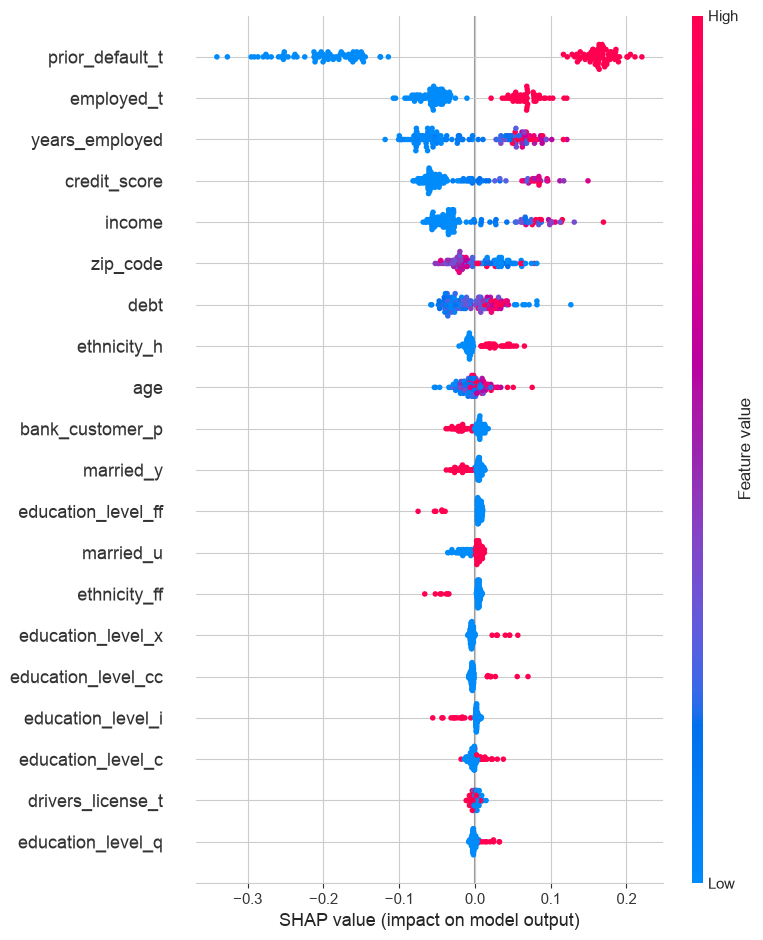

In [14]:
shap.summary_plot(shap_values_approved, X_test, show=False)
plt.tight_layout()
plt.savefig('../reports/figures/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

**How to read this chart:** each dot is one applicant in the test set. Red = high value for that
feature, blue = low value. Position left/right shows whether that feature pushed *that applicant's*
prediction toward approval (right) or denial (left). Features are ranked top-to-bottom by overall
impact.

This is the chart that answers: *"if someone has no credit history, what should they focus on first?"*
— look at which features have the widest spread and the clearest color pattern.

## 9. Save the best model (optional, for future use)

In [15]:
import joblib

# Pick whichever model performed best based on the results table above
best_model = rf  # change to log_reg if Logistic Regression scored better

joblib.dump(best_model, '../reports/best_model.pkl')
print("Model saved to reports/best_model.pkl")

Model saved to reports/best_model.pkl


## Summary

- Best performing model: Random Forest Model outperformed Logistic Regression in 
nearly every metric (Accuracy: .884 vs .870, precision: .881 vs .831, 
ROC-AUC .954 vs .946) with Logistic Regression scoring better on recall: .885 vs .852
- Key metric values (accuracy / precision / recall / ROC-AUC): 
Logistic Regression - (.870 / .831 / .885 / .946)
Random Forest       - (.884 / .881 / .852 / .954)
- Top 3 features driving approval (from SHAP): No Prior Default, Income, and Credit Score appeared to be the top features driving approval.
- Concrete, plain-language takeaway for someone with no credit history: 
For someone building credit from scratch, the model suggests prioritizing a clean payment
history (avoiding defaults) and demonstrating a steady income before applying. Credit score itself compounds overtime, so starting with a secured card or becoming an authorized user
are both advisable and recommended if/when available. These factors seem to matter more than any single application detail, signaling the groudwork for approval is built well before
you ever fill out a credit card application. 
- Any limitations of this model worth noting: The protections regarding privacy caused
for a limited dataset, seen in the variables. In some of the features, education level pushed
towards approval, while in others it pushed towards denial. One might assume higher
level of education indicates higher levels of approvals, possibly making it a higher 
driving feature towards approval, but without proper data labels, this assumption 
cannot be safely made. 
